## Global sensitivity analysis of the spinning dust SED features to the grain and environmental parameters.

In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import matplotlib.patches as mpatches
from matplotlib.colors import to_rgba
import warnings
warnings.filterwarnings('ignore')

# Add the root directory of the package to sys.path
sys.path.append('/Users/zzhang/Workspace/SpyDust/')
sys.path.append('../')

In [2]:
# Configure matplotlib for publication quality
plt.rcParams.update({
    'font.size': 12,
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'DejaVu Serif', 'Bitstream Vera Serif', 'serif'],
    'text.usetex': False,  # Set to True if LaTeX is available
    'figure.figsize': [10, 8],
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'savefig.format': 'pdf',
    'axes.linewidth': 1.2,
    'axes.labelsize': 14,
    'axes.titlesize': 16,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'lines.linewidth': 2,
    'lines.markersize': 6
})

In [3]:
# Check which font is actually being used
import matplotlib.font_manager as fm
font_prop = fm.FontProperties(family='serif')
print(f"Active serif font: {font_prop.get_name()}")
print(f"Available serif fonts: {[f.name for f in fm.fontManager.ttflist if 'serif' in f.name.lower()][:5]}")  # Show first 5

Active serif font: Times New Roman
Available serif fonts: ['DejaVu Serif', 'DejaVu Serif', 'DejaVu Serif', 'DejaVu Serif Display', 'DejaVu Serif']


In [4]:
# Import SpyDust modules
import functools
import SpyDust.Grain as Grain
from SpyDust.SpyDust import SpyDust_given_grain_size_shape
from SpyDust.util import makelogtab, cgsconst
from SpyDust.SPDUST_as_is import emissivity
import matplotlib.cm as cm


l_a computed
readPAH computed
Loaded previously computed Jpeisrf arrays from file.
Tev table already exists at /Users/zzhang/Workspace/SpyDust/SpyDust/Data_Files/Tev_30a_30chi.txt.
I(Zg<0, parabolic) stored
I(rot, e, Zg <> 0) stored
I(Zg<0, parabolic) stored
I(rot, e, Zg <> 0) stored
Gaunt factor stored
l_a computed
readPAH computed
Loaded previously computed Jpeisrf arrays from file.
Maximum energy in the Qabs_hnu_tab is 1239.84 eV.
FIR_integral_charged shape: (30, 30)
Na: 30, Nchi: 30
Tev table already exists at /Users/zzhang/Workspace/SpyDust/SpyDust/Data_Files/Tev_30a_30chi.txt.
Gaunt factor stored


In [5]:
freqs = np.loadtxt('data_revision/freq.txt')
MC_params = np.loadtxt('data_revision/MC_params.txt')
MC_sed_tumbling = np.loadtxt('data_revision/MC_SED_tumbling.txt')
MC_sed_no_tumbling = np.loadtxt('data_revision/MC_SED_no_tumbling.txt')

# Remove unphysical SEDs (nan or negative values)
valid_indices_tumbling = ~np.isnan(MC_sed_tumbling).any(axis=1) & (MC_sed_tumbling > 0).all(axis=1)
MC_sed_tumbling = MC_sed_tumbling[valid_indices_tumbling]
MC_params_tumbling = MC_params[valid_indices_tumbling]

valid_indices_no_tumbling = ~np.isnan(MC_sed_no_tumbling).any(axis=1) & (MC_sed_no_tumbling > 0).all(axis=1)
MC_sed_no_tumbling = MC_sed_no_tumbling[valid_indices_no_tumbling]
MC_params_no_tumbling = MC_params[valid_indices_no_tumbling]

from SpyDust.SED_fit import fit_sed_ensemble

MC_features_tumbling = fit_sed_ensemble(
    freqs,
    MC_sed_tumbling,
    thres=1e-3
)
MC_features_tumbling[:,0] = np.exp(MC_features_tumbling[:,0])  # Convert log(nu_peak) to nu_peak

MC_features_no_tumbling = fit_sed_ensemble(
    freqs,
    MC_sed_no_tumbling,
    thres=1e-3
)
MC_features_no_tumbling[:,0] = np.exp(MC_features_no_tumbling[:,0])  # Convert log(nu_peak) to nu_peak

100%|██████████| 99999/99999 [00:14<00:00, 6757.30it/s]


In [6]:
MC_catalogue = [[21.3, 0.53], 
                [24.3, 0.78],
                [18.9, 0.46],
                [15.3, 0.59],
                [17.5, 0.57],
                [17.8, 0.47],
                [32.6, 0.65],
                [23.4, 0.51],
                [20.3, 0.60],
                [25.4, 0.72],
                [18.8, 0.58],
                [19.4, 0.68],
                [19.6, 0.89],
                [24.8, 0.48],
                [21.3, 0.62],
                [23.0, 0.50],
                [18.4, 0.58],
                [20.3, 0.57],
                [28.9, 0.53],
                [28.2, 0.53]]

MC_catalogue = np.array(MC_catalogue)

In [7]:
from SpyDust.Grain import N_C, N_H, grain_distribution, grainparams

mu_1d_7 = np.sqrt(N_C(1e-7) + N_H(1e-7)) * 0.2
print(mu_1d_7)

4.8373546489791295


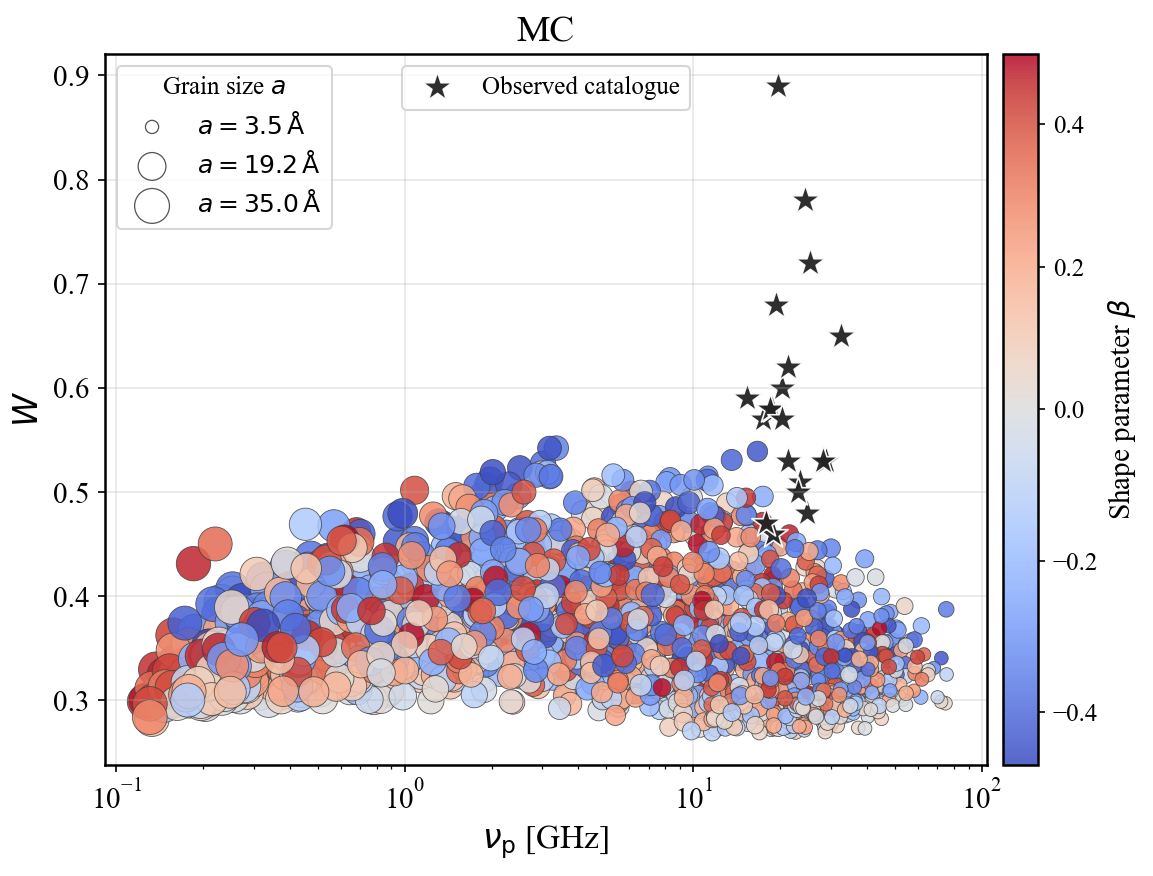

In [15]:
import matplotlib.colors as mcolors

Num=2000

grain_sizes = MC_params_no_tumbling[:Num, -2]  # typically the sampled grain size a
beta_values = MC_params_no_tumbling[:Num, -1]   # typically the shape parameter beta

size_min = grain_sizes.min()
size_max = grain_sizes.max()

size_span = size_max - size_min if size_max > size_min else 1.0

size_min_area = 40.0
size_max_area = 280.0

def _marker_area(values):
    values = np.asarray(values)
    fraction = (values - size_min) / size_span
    scaled = np.clip(fraction, 0.0, 1.0) ** 0.8  # soften the dynamic range
    return size_min_area + (size_max_area - size_min_area) * scaled

marker_sizes = _marker_area(grain_sizes)

if np.any(beta_values < 0) and np.any(beta_values > 0):
    norm = mcolors.TwoSlopeNorm(vmin=beta_values.min(), vcenter=0.0, vmax=beta_values.max())
else:
    norm = mcolors.Normalize(vmin=beta_values.min(), vmax=beta_values.max())

fig, ax = plt.subplots(figsize=(8, 6))

scatter = ax.scatter(
    MC_features_tumbling[:Num, 0],
    MC_features_tumbling[:Num, 1],
    c=beta_values,
    cmap="coolwarm",
    norm=norm,
    s=marker_sizes,
    alpha=0.85,
    edgecolors="0.25",
    linewidth=0.4
)

# scatter_no_tumbling = ax.scatter(
#     MC_features_no_tumbling[:Num, 0],
#     MC_features_no_tumbling[:Num, 1],
#     c="lightgray",
#     norm=norm,
#     s=marker_sizes,
#     alpha=0.85,
#     edgecolors="0.25",
#     linewidth=0.4
# )

obs_handle = ax.scatter(
    MC_catalogue[:, 0],
    MC_catalogue[:, 1],
    marker="*",
    s=220,
    c="#222222",
    edgecolors="white",
    linewidth=0.8,
    alpha=0.95,
    label="Observed catalogue"
)

ax.set_xlabel(r"$\nu_{\rm p}$ [GHz]", fontsize=16)
ax.set_ylabel(r"$W$", fontsize=16)
ax.set_xscale("log")
ax.grid(True, alpha=0.3)
ax.tick_params(axis="both", which="both", labelsize=14)

cbar = plt.colorbar(scatter, ax=ax, pad=0.015)
cbar.set_label(r"Shape parameter $\beta$", fontsize=14)
cbar.ax.tick_params(labelsize=12)

size_labels = np.linspace(size_min, size_max, 3)
size_handles = [
    ax.scatter([], [], s=_marker_area(val), facecolors="none", edgecolors="0.25", linewidth=0.6, alpha=0.9,
               label=fr"$a = {val*1e8:.1f}\,\mathrm{{\AA}}$")
    for val in size_labels
]

legend1 = ax.legend(
    handles=size_handles,
    title=r"Grain size $a$",
    loc="upper left",
    frameon=True,
    fontsize=12,
    title_fontsize=12
)
ax.add_artist(legend1)

legend2 = ax.legend([obs_handle], ["Observed catalogue"], loc="upper center", frameon=True, fontsize=12)

ax.set_title("MC", fontsize=18)

plt.savefig("MC_catalogue_single.pdf")
plt.tight_layout()
plt.show()

In [9]:
from mcpost import gsa_pipeline

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


In [10]:
# X=MC_params_no_tumbling
import copy

# Get indices where peak frequencies are larger than 5GHz.
X = copy.deepcopy(MC_params_tumbling)
Y= copy.deepcopy(MC_features_tumbling)

mask = (Y[:, 0] > 10) & (Y[:, 0] < 100)
idx = np.where(mask)[0]
print(f"Selected {len(idx)} samples out of {X.shape[0]} based on peak frequency criteria.")

X=X[idx, :]
Y=Y[idx, :]

Num=5000
X=X[:Num, :]
Y=Y[:Num, :]

X[:, -2] = np.log(X[:, -2])

# # Reload the module to get latest changes
# import importlib
# importlib.reload(sys.modules['gsa_pipeline'])
# from gsa_pipeline import gsa_pipeline


# Your arrays
# X: (N_samples, N_params)
# Y: (N_samples, 2)  # columns: [peak_frequency, width]
param_names = ["nh","T","Chi","xh","xC","y", "dipole", "log_a","beta"]  # adjust to your order

out = gsa_pipeline(
    X, Y,
    feature_names=["nu_peak", "width"],
    param_names=param_names,
    scaler="standard",            # try "minmax" or None as well
    kernel_kind="rbf",             # try "rbf", "matern32", "matern52", "rq"
    ard=True,
    length_scale_init=1.0,        # or np.ones(d_kept) after dropping consts (handled internally)
    enable_perm=True,
    enable_gp=True,
    enable_sobol=True,
    make_pdp=True,
    N_sobol=1024,                 # increase for tighter Sobol CIs
    drop_const_atol=0.0,
    topk_pdp=3,
    pdp_prefix="pdp_demo",
    gp_random_state=0,
)

table_peak  = out["results"]["nu_peak"]["table"]
table_width = out["results"]["width"]["table"]
print(table_peak.round(4))
print(table_width.round(4))

Selected 36304 samples out of 99990 based on peak frequency criteria.
            MI    dCor  PermMean  PermStd    ARD_LS      S1  S1_conf      ST  \
log_a   0.4052  0.6980    1.4495   0.0613    2.3582  0.7493   0.0745  0.8358   
xC      0.1018  0.3296    0.6486   0.0288    1.1967  0.0580   0.0271  0.0996   
dipole  0.0208  0.1729    0.1957   0.0099    6.5240  0.0713   0.0243  0.1005   
nh      0.0279  0.1439    0.0868   0.0065    3.6460  0.0166   0.0142  0.0291   
beta    0.0056  0.0939    0.0846   0.0049    6.7192  0.0410   0.0180  0.0481   
Chi     0.0000  0.0268    0.0025   0.0003    3.3484  0.0019   0.0040  0.0025   
T       0.0000  0.0218    0.0012   0.0003   68.1555  0.0012   0.0040  0.0022   
y       0.0169  0.0155    0.0000   0.0002  100.0000 -0.0001   0.0003  0.0000   

        ST_conf  1/ARD_LS  AggRank  
log_a    0.0774    0.4241      1.2  
xC       0.0185    0.8356      2.0  
dipole   0.0111    0.1533      3.4  
nh       0.0055    0.2743      4.0  
beta     0.0064    0.148

In [11]:
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.colors import Normalize
from IPython.display import Latex, Markdown, display

def plot_sensitivity_metrics(table, metrics=None, title="Global sensitivity summary", cmap="viridis"):
    """Plot selected sensitivity metrics as a heatmap using matplotlib only."""
    df = pd.DataFrame(table)
    for col in ('ARD_LS',):
        if col in df.columns and col != '1/ARD_LS':
            df = df.drop(columns=[col])
    if metrics is not None:
        missing = [m for m in metrics if m not in df.columns]
        if missing:
            raise ValueError(f"Metrics not found in table: {missing}")
        df_plot = df.loc[:, metrics]
    else:
        numeric_cols = df.select_dtypes(include=[np.number]).columns
        if numeric_cols.empty:
            raise ValueError("No numeric columns available for plotting.")
        df_plot = df.loc[:, numeric_cols]

    df_plot = df_plot.astype(float)
    order = df_plot.sort_values(df_plot.columns[0], ascending=False).index
    df_plot = df_plot.loc[order]

    data = df_plot.values
    norm = Normalize(vmin=np.nanmin(data), vmax=np.nanmax(data))

    try:
        cmap_obj = plt.get_cmap(cmap)
    except ValueError as exc:
        raise ValueError(f"Invalid colormap '{cmap}'. Try one of: {plt.colormaps()}" ) from exc

    fig_width = 1.8 * df_plot.shape[1] + 2
    fig_height = 0.6 * df_plot.shape[0] + 2
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    im = ax.imshow(data, aspect='auto', cmap=cmap_obj, norm=norm)
    cbar = fig.colorbar(im, ax=ax, pad=0.015)
    cbar.set_label("Relative importance")

    ax.set_xticks(range(df_plot.shape[1]))
    ax.set_xticklabels(df_plot.columns, rotation=45, ha='right')
    ax.set_yticks(range(df_plot.shape[0]))
    ax.set_yticklabels(df_plot.index)

    threshold = (norm.vmax + norm.vmin) / 2 if np.isfinite(norm.vmax) and np.isfinite(norm.vmin) else np.nanmean(data)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            value = data[i, j]
            text = f"{value:.3f}"
            text_color = 'white' if value > threshold else 'black'
            ax.text(j, i, text, ha='center', va='center', color=text_color)

    ax.set_title(title, fontsize=14, pad=12)
    ax.set_xlabel("Metric")
    ax.set_ylabel("Parameter")
    fig.tight_layout()
    return fig, ax

def sensitivity_table_to_latex(table, caption=None, label=None,
                               float_format="{:.3f}", column_format=None,
                               display_result=False, fallback_markdown=True,
                               feature_label=None):
    """Return a LaTeX table string from a sensitivity summary table."""
    df = pd.DataFrame(table)
    for col in ('ARD_LS',):
        if col in df.columns and col != '1/ARD_LS':
            df = df.drop(columns=[col])

    numeric_cols = df.select_dtypes(include=[np.number]).columns
    df.loc[:, numeric_cols] = df.loc[:, numeric_cols].astype(float)

    df.index = [str(idx).replace('_', r'\_') for idx in df.index]
    df = df.rename_axis("Parameter").reset_index()

    if feature_label:
        label_tex = str(feature_label).replace('_', r'\_')
        multirow = f"\\multirow{{{len(df)}}}{{*}}{{{label_tex}}}"
        feature_col = [''] * len(df)
        feature_col[0] = multirow
        df.insert(0, 'Feature', feature_col)

    formatter = None if float_format is None else (lambda x: float_format.format(x))

    latex_str = df.to_latex(index=False, escape=False, caption=caption, label=label,
                            column_format=column_format, float_format=formatter)
    if display_result:
        try:
            display(Latex(latex_str))
        except Exception:
            if fallback_markdown:
                display(Markdown(f"```latex\n{latex_str}\n```"))
            else:
                raise
    return latex_str

In [12]:
print(sensitivity_table_to_latex(table_peak, feature_label="peak"))

\begin{tabular}{llrrrrrrrrrr}
\toprule
Feature & Parameter & MI & dCor & PermMean & PermStd & S1 & S1_conf & ST & ST_conf & 1/ARD_LS & AggRank \\
\midrule
\multirow{8}{*}{peak} & log\_a & 0.405 & 0.698 & 1.450 & 0.061 & 0.749 & 0.075 & 0.836 & 0.077 & 0.424 & 1.200 \\
 & xC & 0.102 & 0.330 & 0.649 & 0.029 & 0.058 & 0.027 & 0.100 & 0.019 & 0.836 & 2.000 \\
 & dipole & 0.021 & 0.173 & 0.196 & 0.010 & 0.071 & 0.024 & 0.100 & 0.011 & 0.153 & 3.400 \\
 & nh & 0.028 & 0.144 & 0.087 & 0.006 & 0.017 & 0.014 & 0.029 & 0.006 & 0.274 & 4.000 \\
 & beta & 0.006 & 0.094 & 0.085 & 0.005 & 0.041 & 0.018 & 0.048 & 0.006 & 0.149 & 5.200 \\
 & Chi & 0.000 & 0.027 & 0.003 & 0.000 & 0.002 & 0.004 & 0.002 & 0.000 & 0.299 & 5.700 \\
 & T & 0.000 & 0.022 & 0.001 & 0.000 & 0.001 & 0.004 & 0.002 & 0.000 & 0.015 & 7.100 \\
 & y & 0.017 & 0.015 & 0.000 & 0.000 & -0.000 & 0.000 & 0.000 & 0.000 & 0.010 & 7.400 \\
\bottomrule
\end{tabular}



In [13]:
print(sensitivity_table_to_latex(table_width, feature_label="width"))

\begin{tabular}{llrrrrrrrrrr}
\toprule
Feature & Parameter & MI & dCor & PermMean & PermStd & S1 & S1_conf & ST & ST_conf & 1/ARD_LS & AggRank \\
\midrule
\multirow{8}{*}{width} & xC & 0.350 & 0.639 & 0.851 & 0.035 & 0.216 & 0.044 & 0.264 & 0.029 & 0.800 & 1.200 \\
 & log\_a & 0.260 & 0.588 & 0.661 & 0.024 & 0.560 & 0.063 & 0.656 & 0.054 & 0.537 & 1.800 \\
 & beta & 0.188 & 0.210 & 0.128 & 0.006 & 0.043 & 0.021 & 0.067 & 0.008 & 0.353 & 3.400 \\
 & nh & 0.013 & 0.131 & 0.052 & 0.003 & 0.017 & 0.018 & 0.041 & 0.006 & 0.360 & 4.800 \\
 & dipole & 0.022 & 0.065 & 0.009 & 0.001 & 0.003 & 0.018 & 0.051 & 0.010 & 0.235 & 5.200 \\
 & T & 0.018 & 0.125 & 0.047 & 0.003 & 0.032 & 0.019 & 0.045 & 0.005 & 0.119 & 5.400 \\
 & Chi & 0.000 & 0.041 & 0.004 & 0.000 & -0.003 & 0.008 & 0.010 & 0.002 & 0.381 & 6.300 \\
 & y & 0.000 & 0.020 & 0.000 & 0.000 & 0.000 & 0.000 & 0.000 & 0.000 & 0.010 & 7.900 \\
\bottomrule
\end{tabular}

